# DATA 266 – CLIP: Caption–Image Similarity & Zero-Shot CIFAR-10

**Part 1** – Compare one caption against many images (100 per class, CIFAR-10) using CLIP embeddings and cosine similarity.
**Part 2** – Zero-shot classification of the CIFAR-10 test set with CLIP, with per-class accuracy and a confusion matrix.

In [1]:
import torch, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from torchvision.datasets import CIFAR10
from transformers import CLIPModel, CLIPProcessor
from sklearn.metrics import confusion_matrix, accuracy_score

torch.manual_seed(0); np.random.seed(0)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

C:\Users\rohil2\clip-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1116 14:56:30.330000 67076 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


device: cuda


## 1. Load the CLIP model

In [2]:
MODEL = 'openai/clip-vit-base-patch32'
model = CLIPModel.from_pretrained(MODEL).to(device).eval()
processor = CLIPProcessor.from_pretrained(MODEL)

def _as_tensor(x):
    # transformers versions differ: tensor vs. output object
    return x if torch.is_tensor(x) else x.pooler_output

@torch.no_grad()
def embed_images(pil_images, bs=256):
    out = []
    for i in range(0, len(pil_images), bs):
        px = processor(images=pil_images[i:i+bs], return_tensors='pt')['pixel_values'].to(device)
        f = _as_tensor(model.get_image_features(pixel_values=px))
        out.append(torch.nn.functional.normalize(f, dim=-1).cpu())   # L2-normalise
    return torch.cat(out)

@torch.no_grad()
def embed_text(texts):
    t = processor(text=texts, return_tensors='pt', padding=True).to(device)
    f = _as_tensor(model.get_text_features(**t))
    return torch.nn.functional.normalize(f, dim=-1).cpu()

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 25063.55it/s]

## 2. Load CIFAR-10

In [3]:
train = CIFAR10(root='./data', train=False, download=True)   # 10,000 test images (PIL, 32x32)
classes = train.classes
labels = np.array(train.targets)
print(classes, len(train))

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck'] 10000


# Part 1 – Caption vs. images

**Define the caption**, then **select 100 images from each of the 10 classes** (1,000 images total).

In [4]:
CAPTION = 'a photo of a dog'

rng = np.random.default_rng(0)
idx = np.concatenate([rng.choice(np.where(labels == c)[0], 100, replace=False) for c in range(10)])
sub_images = [train[i][0] for i in idx]
sub_labels = labels[idx]
print(len(sub_images), 'images,', np.bincount(sub_labels))

1000 images, [100 100 100 100 100 100 100 100 100 100]


**Preprocess** (CLIP processor: resize to 224, centre-crop, normalise) → **extract & normalise embeddings** → **cosine similarity** (dot product of unit vectors).

In [5]:
img_emb = embed_images(sub_images)                 # (1000, 512), unit norm
txt_emb = embed_text([CAPTION])                    # (1, 512),   unit norm
print('norms:', img_emb.norm(dim=-1)[:3].tolist(), txt_emb.norm(dim=-1).tolist())

sims = (img_emb @ txt_emb.T).squeeze(1).numpy()    # cosine similarity
df = pd.DataFrame({'idx': idx, 'label': [classes[l] for l in sub_labels], 'sim': sims})
df.groupby('label')['sim'].agg(['mean','std','min','max']).sort_values('mean', ascending=False).round(4)

norms: [0.9999999403953552, 1.0, 0.9999999403953552] [0.9999999403953552]


,mean,std,min,max
label,,,,
dog,0.2583,0.0109,0.2068,0.2756
cat,0.2370,0.0132,0.2049,0.2656
deer,0.2326,0.0157,0.1949,0.2638
frog,0.2276,0.0141,0.1833,0.2607
bird,0.2249,0.0133,0.1970,0.2557
horse,0.2205,0.0114,0.1914,0.2517
airplane,0.2044,0.0145,0.1658,0.2552
automobile,0.2012,0.0112,0.1732,0.2287
truck,0.1965,0.0107,0.1741,0.2232


### Visualise: distribution of similarity per class

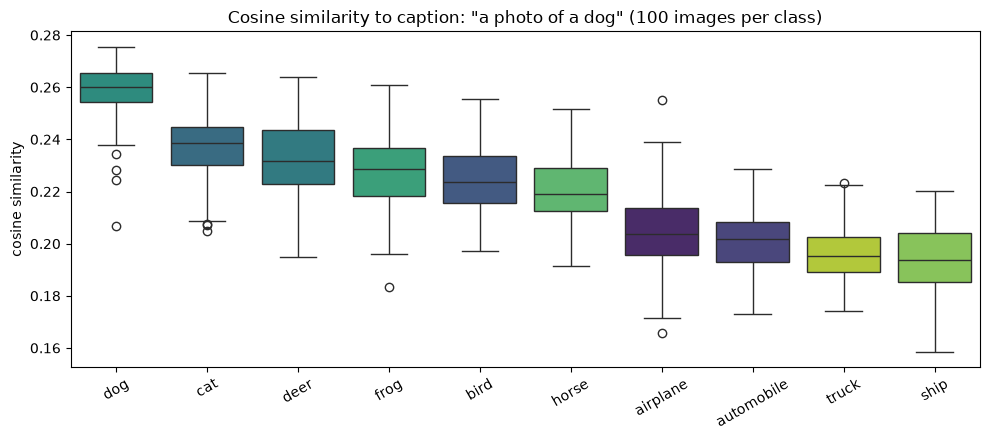

In [6]:
order = df.groupby('label')['sim'].mean().sort_values(ascending=False).index
plt.figure(figsize=(10,4.5))
sns.boxplot(data=df, x='label', y='sim', order=order, hue='label', legend=False, palette='viridis')
plt.title(f'Cosine similarity to caption: "{CAPTION}" (100 images per class)')
plt.ylabel('cosine similarity'); plt.xlabel(''); plt.xticks(rotation=30)
plt.tight_layout(); plt.savefig('similarity_by_class.png', dpi=150); plt.show()

### Visualise: images with their similarity scores (top 12, bottom 12 out of 1,000)

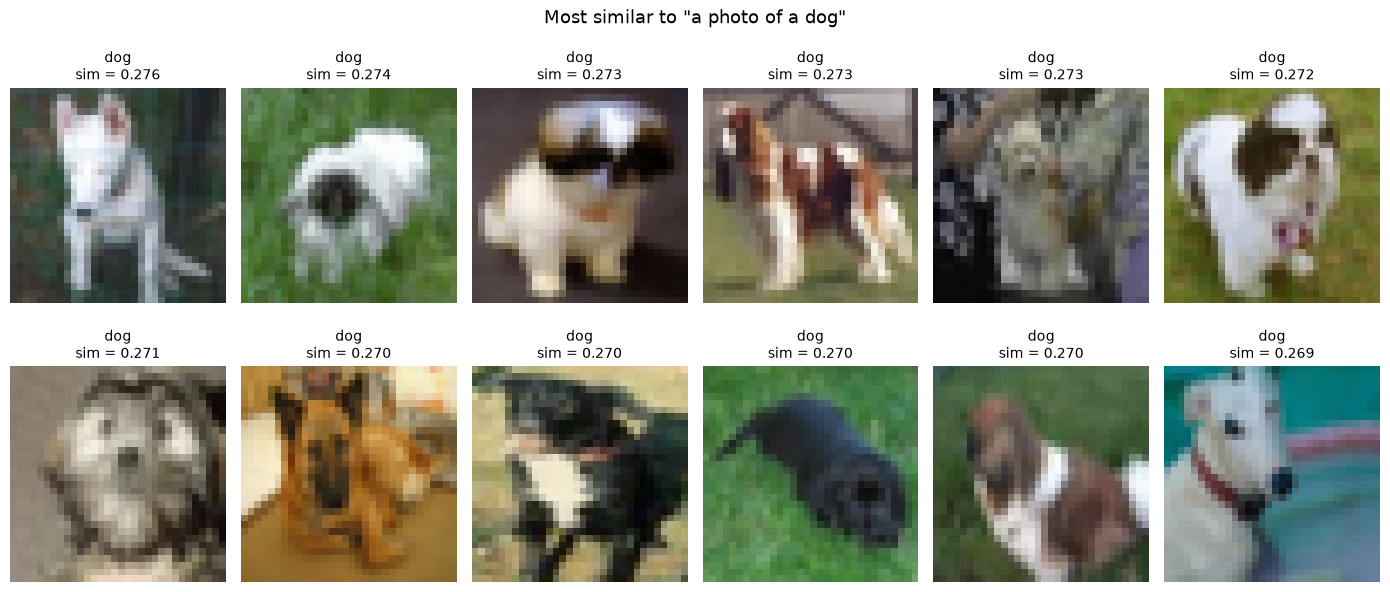

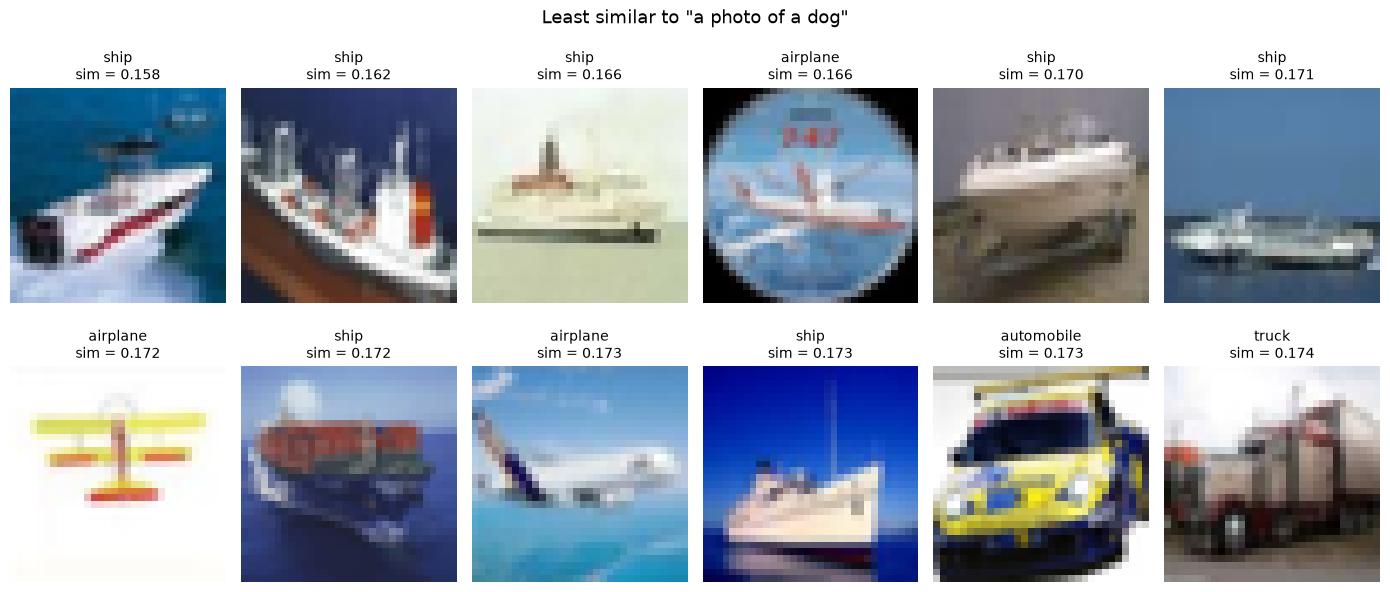

In [7]:
def show(rows, title, fname):
    fig, axes = plt.subplots(2, 6, figsize=(14, 6.4))
    for ax, (_, r) in zip(axes.ravel(), rows.iterrows()):
        ax.imshow(train[int(r.idx)][0]); ax.axis('off')
        ax.set_title(f'{r.label}\nsim = {r.sim:.3f}', fontsize=10)
    fig.suptitle(title, fontsize=13); plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

s = df.sort_values('sim', ascending=False)
show(s.head(12), f'Most similar to "{CAPTION}"', 'top_similar.png')
show(s.tail(12).iloc[::-1], f'Least similar to "{CAPTION}"', 'least_similar.png')

### Same analysis for a second caption (does the ranking follow the caption?)

label
airplane      0.2452
bird          0.1974
frog          0.1859
ship          0.1848
deer          0.1846
dog           0.1806
cat           0.1788
horse         0.1714
truck         0.1694
automobile    0.1672
Name: sim, dtype: float64


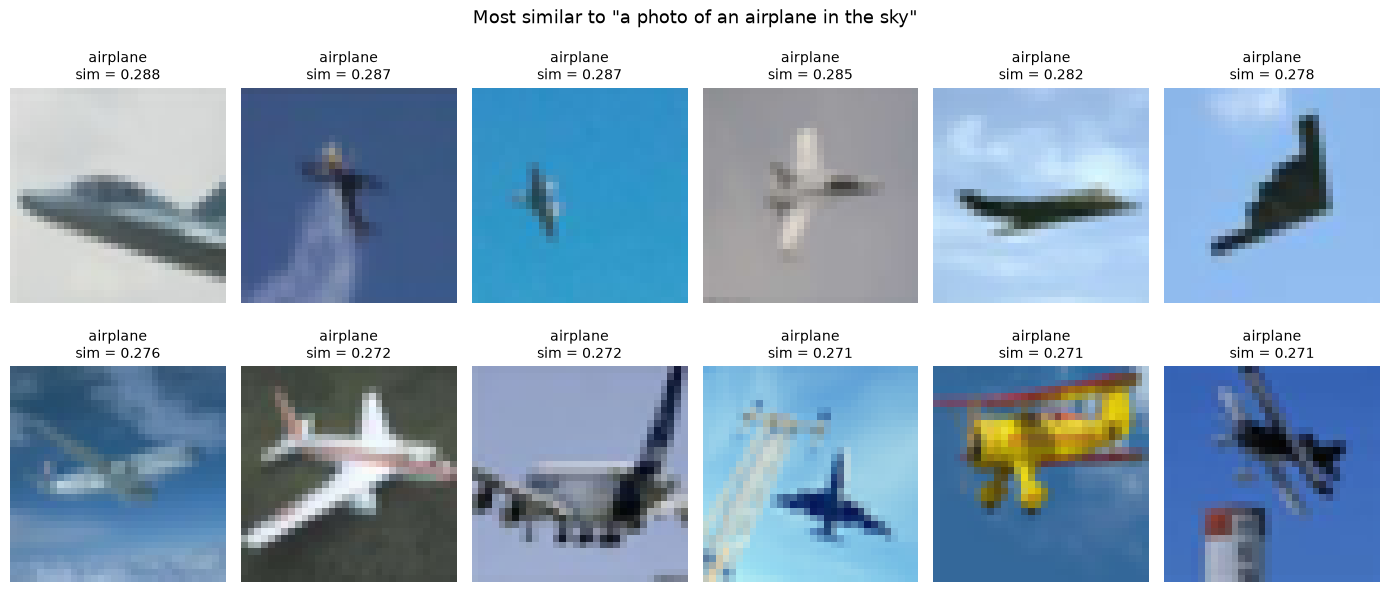

In [8]:
CAPTION2 = 'a photo of an airplane in the sky'
sims2 = (img_emb @ embed_text([CAPTION2]).T).squeeze(1).numpy()
df2 = pd.DataFrame({'idx': idx, 'label': [classes[l] for l in sub_labels], 'sim': sims2})
print(df2.groupby('label')['sim'].mean().sort_values(ascending=False).round(4))
show(df2.sort_values('sim', ascending=False).head(12), f'Most similar to "{CAPTION2}"', 'top_similar_caption2.png')

# Part 2 – Zero-shot classification on CIFAR-10

Each class name becomes a prompt (`"a photo of a {class}"`). An image is assigned the class whose text embedding has the highest cosine similarity. No training involved. Evaluated on all **10,000** test images.

In [9]:
prompts = [f'a photo of a {c}' for c in classes]
txt_cls = embed_text(prompts)                                   # (10, 512)
all_emb = embed_images([train[i][0] for i in range(len(train))])   # (10000, 512)
logits = 100.0 * all_emb @ txt_cls.T                           # CLIP logit scale
pred = logits.argmax(1).numpy()
print(f'overall accuracy: {accuracy_score(labels, pred):.4f}')

overall accuracy: 0.8880


In [10]:
cm = confusion_matrix(labels, pred)
per_class = cm.diagonal() / cm.sum(1)
acc_df = pd.DataFrame({'class': classes, 'accuracy': per_class.round(4), 'n': cm.sum(1)})
print(acc_df.to_string(index=False))
print('\nmean per-class accuracy:', per_class.mean().round(4))

     class  accuracy    n
  airplane     0.901 1000
automobile     0.976 1000
      bird     0.888 1000
       cat     0.860 1000
      deer     0.765 1000
       dog     0.884 1000
      frog     0.774 1000
     horse     0.976 1000
      ship     0.955 1000
     truck     0.901 1000

mean per-class accuracy: 0.888


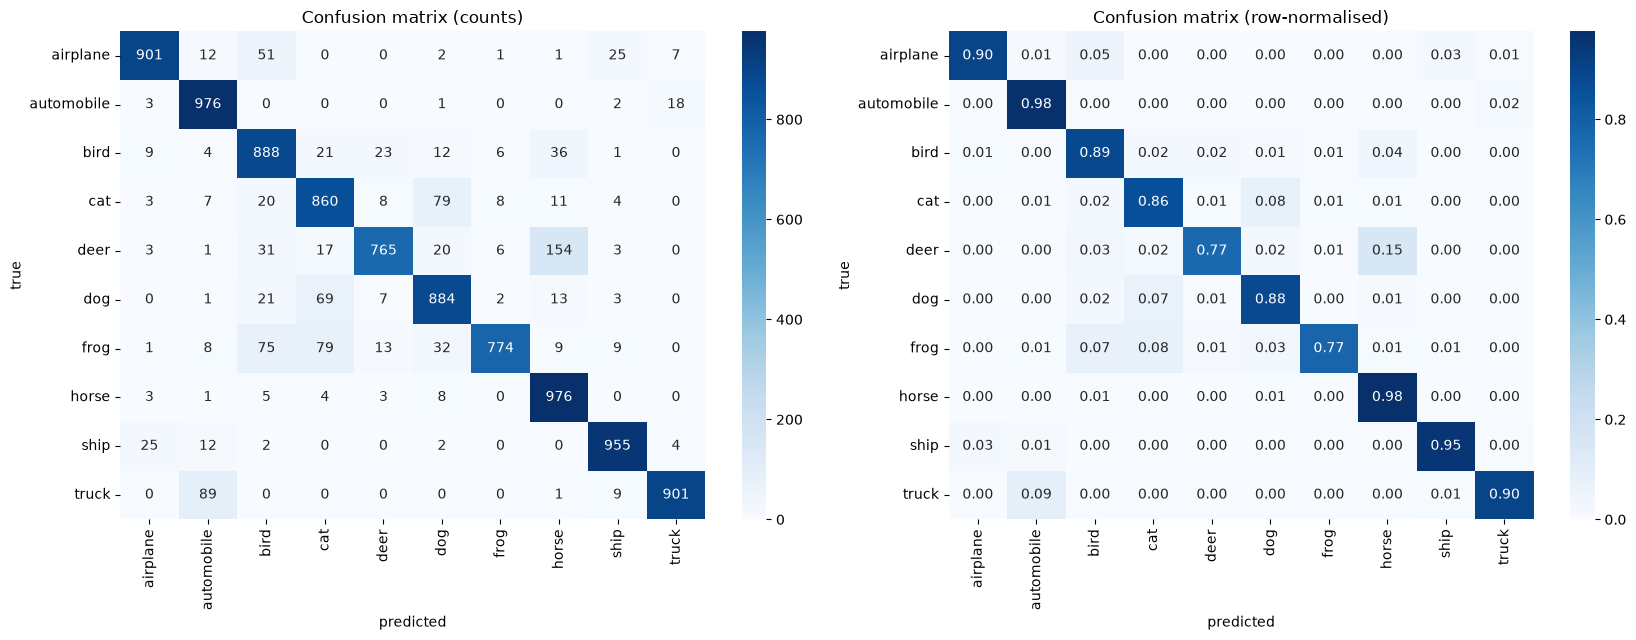

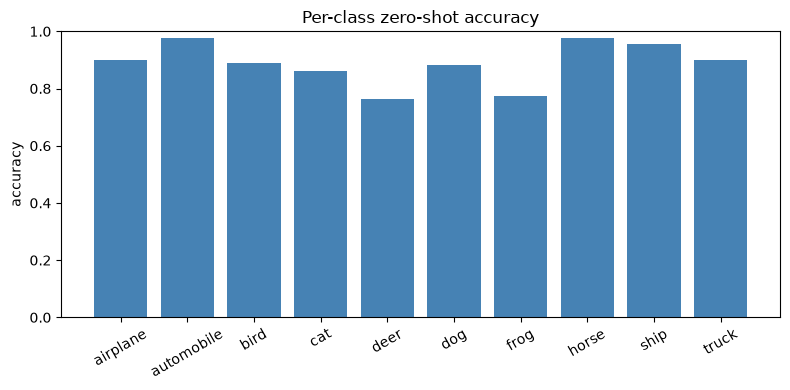

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes, ax=ax[0])
ax[0].set_title('Confusion matrix (counts)'); ax[0].set_xlabel('predicted'); ax[0].set_ylabel('true')
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt='.2f', cmap='Blues', xticklabels=classes, yticklabels=classes, ax=ax[1])
ax[1].set_title('Confusion matrix (row-normalised)'); ax[1].set_xlabel('predicted'); ax[1].set_ylabel('true')
plt.tight_layout(); plt.savefig('confusion_matrix.png', dpi=150); plt.show()

plt.figure(figsize=(8,4)); plt.bar(classes, per_class, color='steelblue')
plt.ylim(0,1); plt.xticks(rotation=30); plt.ylabel('accuracy'); plt.title('Per-class zero-shot accuracy')
plt.tight_layout(); plt.savefig('per_class_accuracy.png', dpi=150); plt.show()

In [12]:
# most frequent confusions
off = [(classes[i], classes[j], cm[i, j]) for i in range(10) for j in range(10) if i != j]
print(pd.DataFrame(off, columns=['true','predicted','count']).sort_values('count', ascending=False).head(8).to_string(index=False))

    true  predicted  count
    deer      horse    154
   truck automobile     89
     cat        dog     79
    frog        cat     79
    frog       bird     75
     dog        cat     69
airplane       bird     51
    bird      horse     36


# Findings

**Setup.** CLIP ViT-B/32 (`openai/clip-vit-base-patch32`), CIFAR-10 test set (32x32 images upsampled to 224x224 by the CLIP processor). Embeddings are L2-normalised, so similarity = cosine similarity.

## Part 1 – Caption vs. images (1,000 images, 100 per class)
* For the caption **"a photo of a dog"**, the *dog* class has the highest mean similarity (**0.258**), followed by cat (0.237), deer (0.233) and frog (0.228). The least similar classes are the vehicles: truck (0.197) and ship (0.194). All 12 top-scoring images are dogs.
* Ordering follows semantic closeness: other animals score higher than vehicles, even though they are not dogs. CLIP's embedding space encodes "animal-ness" as well as the exact class.
* The same behaviour holds for a different caption: for **"a photo of an airplane in the sky"** *airplane* is clearly the top class (0.245 vs. 0.197 for the next, bird).
* Absolute cosine values are small (about 0.16–0.28) and the spread inside a class is narrow (std about 0.01). Cosine values between CLIP image and text embeddings are not calibrated probabilities. What matters is the *relative* ranking, not the raw value.
* The per-class distributions overlap (see the box plot), so a single threshold on similarity alone would not separate "dog" from "not dog" perfectly. Comparing against several class prompts (Part 2) works much better.

## Part 2 – Zero-shot CIFAR-10 classification (10,000 test images)
* **Overall accuracy: 88.8%** with no training, just the prompt "a photo of a {class}".
* **Per-class accuracy:** automobile 97.6%, horse 97.6%, ship 95.5%, airplane 90.1%, truck 90.1%, bird 88.8%, dog 88.4%, cat 86.0%, frog 77.4%, **deer 76.5%** (worst).
* **Main confusions:** deer to horse (154), truck to automobile (89), cat to dog (79), frog to cat (79), frog to bird (75), dog to cat (69). These are visually or semantically similar pairs, which makes them the expected errors at 32x32 resolution.
* **Caveats.** The 32x32 images become blurry when upsampled, which hurts fine-grained animal classes most (deer, frog, cat). A single prompt template is used; prompt ensembling or a larger CLIP model (ViT-L/14) would likely improve accuracy, but was not tested here.